# Mode-I KM-PIKFNN: adaptive exterior source boundary
Adam and L-BFGS jointly optimize kernel coefficients and bounded x/y source-margin factors.
Complex autograd runs on CPU. Optional SVD refresh corrects coefficients only. KI reference is evaluation only.
Set `adaptive_sources=False` for a fixed-source control.


# KM-PIKFNN — CPU complex basis / GPU real coefficient training (v3)

- Exterior source points only; Mode-I Williams n=1,3,5 enrichment.
- ALL complex basis calculations are performed on CPU to avoid CUDA NVRTC DLL errors, including complex negation.
- Only real-valued response matrices are moved to the selected training device; Adam/L-BFGS still use the GPU when available.
- Fixed source coordinates and basis matrices; no gradients with respect to source positions are needed in this notebook.
- Same-objective SVD warm start by default. Set ls_warm_start=False for zero-start training.
- Retain lowest-loss coefficients including initialization; reference KI never enters the loss.
- Restart the notebook kernel and Run All. The first configuration cell prints the devices and version.
- Full execution is tested on CPU; GPU execution cannot be tested in the current environment.


In [1]:
# CUDA compatibility fix v3: ALL complex basis operations run on CPU.
# Only real-valued response matrices and coefficient training use the GPU.
# Revised KM-PIKFNN: exterior sources + Williams n=1,3,5 enrichment.
# Requires: numpy, scipy, torch, matplotlib. Reference K_I is evaluation only.
# Default: SVD warm start + Adam/L-BFGS. Set ls_warm_start=False for zero start.

import math
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.linalg import lstsq as scipy_lstsq


import copy
import csv


In [2]:

# =========================
# 1) Configuration
# =========================

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = {
    # Geometry and loading
    "a": 1.0,
    "b": 2.0,
    "h": 6.0,
    "E": 1.0,
    "nu": 0.30,
    "sigma0": 1.0,
    "plane_strain": True,

    # Boundary collocation
    "n_top": 121,
    "n_side": 121,
    "n_crack": 100,
    "n_ligament": 100,
    "eps_crack": 1.0e-6,

    # Exterior point-force source points
    "n_src_side": 64,
    "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.05,

    # Compatibility settings only: no tip clusters are generated
    "tip_cluster_count": 0,
    "tip_cluster_radii": [0.08, 0.16],
    "tip_cluster_angle_min_deg": 200.0,
    "tip_cluster_angle_max_deg": 340.0,

    # Optimization
    "adam_steps": 500,
    "adaptive_sources": True,
    "source_lr": 1.0e-2,
    "source_margin_x_bounds": [0.02, 0.60],
    "source_margin_y_bounds": [0.01, 0.30],
    "source_log_every": 50,
    "svd_refresh_every": 20,  # coefficient correction at current source locations

    "ls_warm_start": True,
    "svd_rcond": 1.0e-12,
    "higher_williams_orders": [1.5, 2.5],
    "adam_lr": 1.0e-3,
    "lbfgs_epochs": 50,
    "lbfgs_max_iter": 20,
    "lambda_reg": 1.0e-10,

    # Boundary weights
    "w_top": 2.5,
    "w_right": 1.5,
    "w_left": 2.0,
    "w_crack": 8.0,
    "w_ligament": 4.0,

    # Plotting
    "nx_plot": 141,
    "ny_plot": 141,
    "seed": 2026,
}

print("Version: v3_CPU_basis_GPU_train")
print(f"Complex basis device: CPU; real coefficient training device: {device}")
torch.manual_seed(cfg["seed"])
np.random.seed(cfg["seed"])

# Differentiable complex source geometry stays on CPU to avoid Windows NVRTC.
if cfg["adaptive_sources"]:
    device=torch.device("cpu")
    torch.set_num_threads(min(4,torch.get_num_threads()))
print(f"Adaptive source training: {cfg['adaptive_sources']}; device={device}")


Version: v3_CPU_basis_GPU_train
Complex basis device: CPU; real coefficient training device: cuda
Adaptive source training: True; device=cpu


In [3]:

# =========================
# 2) Material constants
# =========================

E = cfg["E"]
nu = cfg["nu"]
mu = E / (2.0 * (1.0 + nu))

if cfg["plane_strain"]:
    lam = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    kappa = 3.0 - 4.0 * nu
else:
    lam = E * nu / (1.0 - nu * nu)
    kappa = (3.0 - nu) / (1.0 + nu)

a = cfg["a"]
b = cfg["b"]
h = cfg["h"]
sigma0 = cfg["sigma0"]


def reference_ki_tada(a_value: float = a, b_value: float = b, sigma: float = sigma0) -> float:
    """Reference SIF used by the benchmark paper."""
    width_factor = 1.0 - 0.025 * (a_value / b_value) ** 2 + 0.06 * (a_value / b_value) ** 4
    finite_width = math.sqrt(1.0 / math.cos(math.pi * a_value / (2.0 * b_value)))
    return sigma * math.sqrt(math.pi * a_value) * width_factor * finite_width


KI_REF = reference_ki_tada()


实际源点数量：252，全部绘制。
边界配点条目总数：563，全部绘制。
边界配点去重后坐标数量：560。
  top: 121
  right: 121
  left: 121
  crack: 100
  ligament: 100


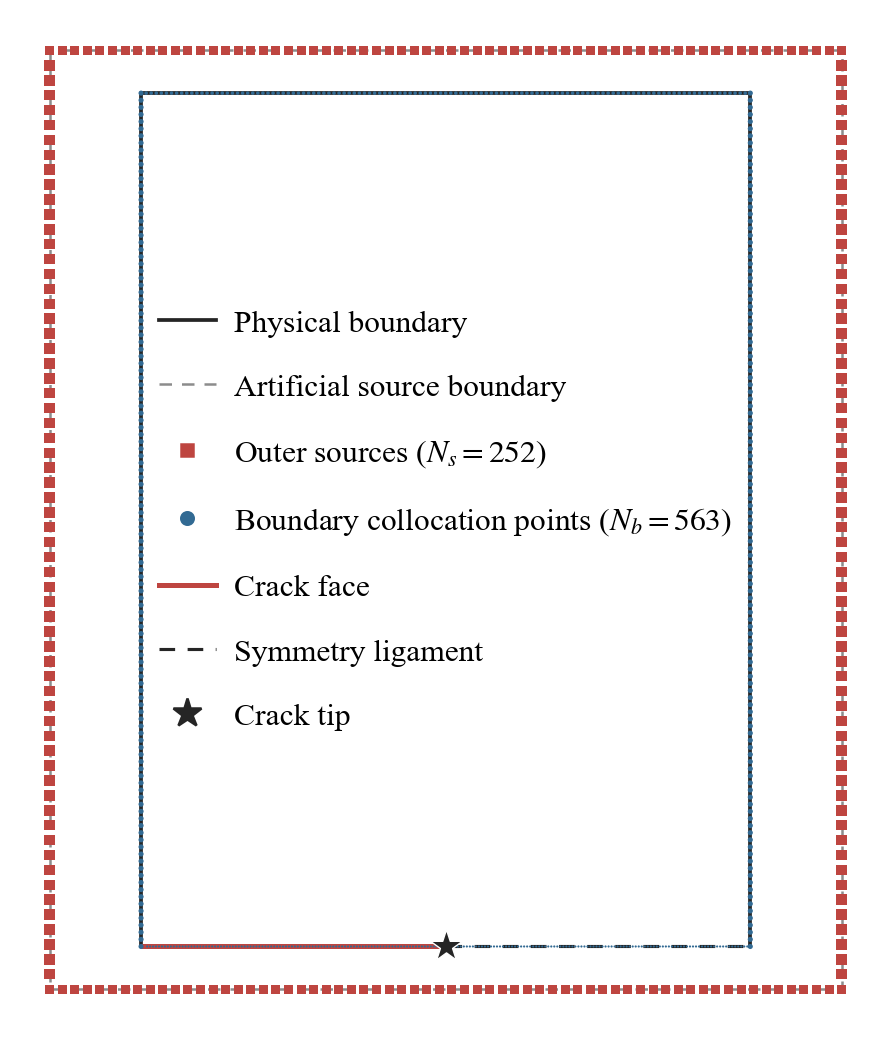

In [4]:

# =========================
# 3) Geometry and source points
# =========================

def linspace_col(x0: float, x1: float, n: int) -> torch.Tensor:
    return torch.linspace(x0, x1, n, device=device).reshape(-1, 1)


def generate_boundary_points() -> dict[str, torch.Tensor]:
    eps = cfg["eps_crack"]

    x_top = linspace_col(0.0, b, cfg["n_top"])
    top = torch.cat([x_top, torch.full_like(x_top, h)], dim=1)

    y_right = linspace_col(0.0, h, cfg["n_side"])
    right = torch.cat([torch.full_like(y_right, b), y_right], dim=1)

    y_left = linspace_col(0.0, h, cfg["n_side"])
    left = torch.cat([torch.zeros_like(y_left), y_left], dim=1)

    x_crack = linspace_col(0.02 * a, 0.98 * a, cfg["n_crack"])
    crack = torch.cat([x_crack, torch.full_like(x_crack, eps)], dim=1)

    x_ligament = linspace_col(1.02 * a, b, cfg["n_ligament"])
    ligament = torch.cat([x_ligament, torch.zeros_like(x_ligament)], dim=1)

    return {
        "top": top,
        "right": right,
        "left": left,
        "crack": crack,
        "ligament": ligament,
    }


def generate_source_points() -> torch.Tensor:
    mx = cfg["src_margin_x_factor"] * b
    my = cfg["src_margin_y_factor"] * h
    n = cfg["n_src_side"]

    xs = torch.linspace(-mx, b + mx, n, device=device)
    ys = torch.linspace(-my, h + my, n, device=device)

    src = []
    for x in xs:
        src.append(torch.stack([x, torch.tensor(-my, device=device)]))
        src.append(torch.stack([x, torch.tensor(h + my, device=device)]))
    for y in ys[1:-1]:
        src.append(torch.stack([torch.tensor(-mx, device=device), y]))
        src.append(torch.stack([torch.tensor(b + mx, device=device), y]))


    return torch.stack(src, dim=0)


bnd_pts = generate_boundary_points()
src_pts = generate_source_points()

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


def _as_numpy_points(points):
    if hasattr(points, "detach"):
        points = points.detach().cpu().numpy()
    return np.asarray(points, dtype=float).reshape(-1, 2)


def plot_mode_i_center_crack_sources(
    cfg,
    bnd_pts,
    src_pts,
    save_name="mode_i_center_crack_source_distribution.png",
    dpi=600,
    figsize=(5.4, 6.0),
    crack_tip_size=180,       # 裂尖五角星面积
    legend_width_ratio=0.94,  # 图例占内部宽度的比例
    show=True,
):
    """全部显示实际源点和边界配点，不抽样、不重新排点。"""
    a, b, h = (float(cfg[k]) for k in ("a", "b", "h"))
    mx = float(cfg["src_margin_x_factor"]) * b
    my = float(cfg["src_margin_y_factor"]) * h

    if not (0 < a < b and h > 0 and mx > 0 and my > 0):
        raise ValueError("需要 0 < a < b、h > 0，且源点外偏移为正。")

    sources = _as_numpy_points(src_pts)
    boundary = {
        name: _as_numpy_points(points)
        for name, points in bnd_pts.items()
    }
    groups = [p for p in boundary.values() if len(p)]
    all_boundary = (
        np.vstack(groups) if groups else np.empty((0, 2))
    )

    n_source = len(sources)
    n_boundary = len(all_boundary)
    n_unique = len(np.unique(all_boundary, axis=0))

    # 与方板受压模板一致
    BLACK = "#252525"
    GRAY = "#8C8C8C"
    RED = "#BE4540"
    BLUE = "#326A93"

    style = {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 11,
        "pdf.fonttype": 42,
        "svg.fonttype": "none",
    }

    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=figsize, dpi=180)
        fig.subplots_adjust(
            left=0.06, right=0.94, bottom=0.045, top=0.975
        )
        ax.set_facecolor("white")

        # 人工源点边界
        ax.plot(
            [-mx, b + mx, b + mx, -mx, -mx],
            [-my, -my, h + my, h + my, -my],
            color=GRAY, lw=1.0, ls=(0, (5, 4)),
            zorder=1,
        )

        # 物理边界：底边由裂面和对称韧带分别绘制
        ax.plot(
            [0, 0, b, b], [0, h, h, 0],
            color=BLACK, lw=1.5, zorder=2,
        )
        ax.plot(
            [0, a], [0, 0],
            color=RED, lw=2.0,
            solid_capstyle="butt", zorder=3,
        )
        ax.plot(
            [a, b], [0, 0],
            color=BLACK, lw=1.25,
            ls=(0, (5, 4)), zorder=3,
        )

        # 保留当前压缩布局，为上下源点留边距，防止标记被裁剪
        xpad = 0.04 * (b + 2 * mx)
        ypad = 0.035 * (h + 2 * my)
        ax.set_xlim(-mx - xpad, b + mx + xpad)
        ax.set_ylim(-my - ypad, h + my + ypad)
        ax.set_aspect("auto")
        ax.set_axis_off()

        fig.canvas.draw()

        def marker_size(points, max_diameter, min_diameter):
            """按画面最近点距选择标记直径，单位为 pt。"""
            points = np.unique(points, axis=0)
            if len(points) < 2:
                return max_diameter ** 2

            pixel_points = ax.transData.transform(points)

            # 分块计算最近点距，避免生成过大的距离矩阵
            nearest = np.inf
            for start in range(0, len(points), 256):
                stop = min(start + 256, len(points))
                delta = (
                    pixel_points[start:stop, None, :]
                    - pixel_points[None, :, :]
                )
                distances = np.sum(delta ** 2, axis=2)
                distances[
                    np.arange(stop - start),
                    np.arange(start, stop),
                ] = np.inf
                nearest = min(nearest, float(distances.min()))

            spacing_pt = np.sqrt(nearest) * 72.0 / fig.dpi
            diameter = np.clip(
                0.72 * spacing_pt,
                min_diameter,
                max_diameter,
            )
            return float(diameter ** 2)

        # 全部实际点：不使用抽样或插值。
        # 各边独立调整点大小，避免密集边上的圆点连成粗线。
        for points in boundary.values():
            if not len(points):
                continue
            ax.scatter(
                points[:, 0], points[:, 1],
                s=marker_size(points, 3.6, 0.65),
                marker="o", color=BLUE,
                edgecolors="none", linewidths=0,
                zorder=4,
            )

        # 源点也按四边分别控制标记尺寸
        covered = np.zeros(n_source, dtype=bool)
        tolerance = 1e-7 * max(b, h)

        for dim, value in (
            (1, -my), (1, h + my),
            (0, -mx), (0, b + mx),
        ):
            mask = (
                np.isclose(
                    sources[:, dim], value,
                    rtol=1e-6, atol=tolerance,
                )
                & ~covered
            )
            covered |= mask
            points = sources[mask]
            if len(points):
                ax.scatter(
                    points[:, 0], points[:, 1],
                    s=marker_size(points, 4.2, 0.8),
                    marker="s", color=RED,
                    edgecolors="none", linewidths=0,
                    zorder=5,
                )

        # 保留不在矩形边界上的其他真实源点
        remaining = sources[~covered]
        if len(remaining):
            ax.scatter(
                remaining[:, 0], remaining[:, 1],
                s=marker_size(remaining, 4.2, 0.8),
                marker="s", color=RED,
                edgecolors="none", linewidths=0,
                zorder=5,
            )

        ax.scatter(
            [a], [0],
            s=crack_tip_size, marker="*",
            color=BLACK, edgecolors="white",
            linewidths=0.55, zorder=7,
        )

        handles = [
            Line2D(
                [], [], color=BLACK, lw=1.5,
                label="Physical boundary",
            ),
            Line2D(
                [], [], color=GRAY, lw=1.0,
                ls=(0, (5, 4)),
                label="Artificial source boundary",
            ),
            Line2D(
                [], [], color=RED,
                marker="s", ls="none", markersize=5,
                label=f"Outer sources ($N_s={n_source}$)",
            ),
            Line2D(
                [], [], color=BLUE,
                marker="o", ls="none", markersize=5,
                label=f"Boundary collocation points ($N_b={n_boundary}$)",
            ),
            Line2D(
                [], [], color=RED, lw=2.0,
                label="Crack face",
            ),
            Line2D(
                [], [], color=BLACK, lw=1.25,
                ls=(0, (5, 4)),
                label="Symmetry ligament",
            ),
            Line2D(
                [], [], color=BLACK,
                marker="*", ls="none", markersize=12,
                label="Crack tip",
            ),
        ]

        legend_options = dict(
            handles=handles,
            loc="center",
            bbox_to_anchor=(b / 2, h / 2),
            bbox_transform=ax.transData,
            frameon=False,
            handlelength=1.8,
            handletextpad=0.6,
            labelspacing=1.15,
            borderaxespad=0,
            borderpad=0,
        )

        # 在内部空白范围内尽量放大图例，避免越过物理边界
        transform = ax.transData.transform
        interior_width = abs(
            transform((b, 0))[0] - transform((0, 0))[0]
        )
        interior_height = abs(
            transform((0, h))[1] - transform((0, 0))[1]
        )

        font_size = 16.0
        legend = ax.legend(fontsize=font_size, **legend_options)

        for _ in range(4):
            fig.canvas.draw()
            box = legend.get_window_extent(
                fig.canvas.get_renderer()
            )
            factor = min(
                legend_width_ratio * interior_width / box.width,
                0.78 * interior_height / box.height,
            )
            if abs(factor - 1.0) < 0.01:
                break
            font_size *= factor
            legend.remove()
            legend = ax.legend(
                fontsize=font_size, **legend_options
            )

        print(f"实际源点数量：{n_source}，全部绘制。")
        print(f"边界配点条目总数：{n_boundary}，全部绘制。")
        print(f"边界配点去重后坐标数量：{n_unique}。")
        for name, points in boundary.items():
            print(f"  {name}: {len(points)}")

        if show:
            plt.show()

    return fig, ax


fig, ax = plot_mode_i_center_crack_sources(
    cfg,
    bnd_pts,
    src_pts,
    figsize=(5.4, 6.0),
    crack_tip_size=180,
)

In [5]:

# =========================
# 4) K-M formulas
# =========================

def km_response(
    z: torch.Tensor,
    phi: torch.Tensor,
    dphi: torch.Tensor,
    ddphi: torch.Tensor,
    psi: torch.Tensor,
    dpsi: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Kolosov-Muskhelishvili displacement and stress formulas."""
    stress_sum = 4.0 * torch.real(dphi)
    stress_diff_complex = 2.0 * (torch.conj(z) * ddphi + dpsi)
    stress_diff = torch.real(stress_diff_complex)
    sigma_xy = 0.5 * torch.imag(stress_diff_complex)
    sigma_xx = 0.5 * (stress_sum - stress_diff)
    sigma_yy = 0.5 * (stress_sum + stress_diff)

    displacement_complex = (kappa * phi - z * torch.conj(dphi) - torch.conj(psi)) / (2.0 * mu)
    ux = torch.real(displacement_complex)
    uy = torch.imag(displacement_complex)
    return ux, uy, sigma_xx, sigma_yy, sigma_xy


In [6]:

# =========================
# 5) Complex-potential basis functions
# =========================

def polynomial_basis_response(
    x: torch.Tensor,
    y: torch.Tensor,
    which: str,
    degree: int,
    coeff: complex,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Low-order polynomial K-M potential terms."""
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    c = torch.as_tensor(coeff, dtype=z.dtype, device=z.device)

    if degree == 0:
        p = torch.ones_like(z)
        dp = torch.zeros_like(z)
        ddp = torch.zeros_like(z)
    elif degree == 1:
        p = z
        dp = torch.ones_like(z)
        ddp = torch.zeros_like(z)
    elif degree == 2:
        p = z * z
        dp = 2.0 * z
        ddp = 2.0 * torch.ones_like(z)
    else:
        raise ValueError("Only degree 0, 1, 2 are used.")

    zero = torch.zeros_like(z)
    if which == "phi":
        return km_response(z, c * p, c * dp, c * ddp, zero, zero)
    if which == "psi":
        return km_response(z, zero, zero, zero, c * p, c * dp)
    raise ValueError(which)


def complex_log_without_nvrtc(q: torch.Tensor) -> torch.Tensor:
    """Principal complex log using real CUDA kernels: log|q| + i atan2."""
    real_part = torch.log(torch.hypot(q.real, q.imag))
    imag_part = torch.atan2(q.imag, q.real)
    return torch.complex(real_part, imag_part)


def complex_power_without_nvrtc(q: torch.Tensor, exponent: float) -> torch.Tensor:
    """Principal q**exponent using real CUDA kernels, same branch as torch pow."""
    radius = torch.hypot(q.real, q.imag)
    angle = torch.atan2(q.imag, q.real)
    amplitude = torch.pow(radius, float(exponent))
    phase = float(exponent) * angle
    return torch.complex(amplitude * torch.cos(phase), amplitude * torch.sin(phase))


def complex_point_force_potential_response(
    x: torch.Tensor,
    y: torch.Tensor,
    sx: torch.Tensor,
    sy: torch.Tensor,
    fx: float,
    fy: float,
    add_kelvin_constant: bool = True,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Point-force fundamental solution written as K-M complex potentials.

    Let P = Fx + i Fy, q = z - zeta.  In the K-M convention used here,

        Phi = - P / [2 pi (kappa + 1)] log(q)
        Psi = kappa * conj(P) / [2 pi (kappa + 1)] log(q)
              + P * conj(zeta) / [2 pi (kappa + 1)] / q

    This pair gives the same stress field as the Kelvin point-force solution.
    Its displacement differs from the usual Kelvin displacement by a constant
    rigid translation.  Setting add_kelvin_constant=True adds a harmless
    constant to Phi so that the displacement also matches the standard Kelvin
    normalization.  Stresses are unchanged by this constant.
    """
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    zeta = torch.complex(sx.reshape(()), sy.reshape(()))
    p_force = torch.as_tensor(complex(fx, fy), dtype=z.dtype, device=z.device)
    q = z - zeta

    den = 2.0 * math.pi * (kappa + 1.0)
    logq = complex_log_without_nvrtc(q)

    phi = -p_force / den * logq
    dphi = -p_force / den / q
    ddphi = p_force / den / (q * q)

    psi = kappa * torch.conj(p_force) / den * logq + p_force * torch.conj(zeta) / den / q
    dpsi = kappa * torch.conj(p_force) / den / q - p_force * torch.conj(zeta) / den / (q * q)

    if add_kelvin_constant:
        # Adds a constant displacement P / [4 pi mu (kappa + 1)].
        # This only shifts displacement, not stress.
        phi = phi + p_force / (2.0 * math.pi * kappa * (kappa + 1.0))

    return km_response(z, phi, dphi, ddphi, psi, dpsi)


def mode_i_tip_response(
    x: torch.Tensor,
    y: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Unit-K_I Mode-I crack-tip asymptotic field at the right tip (a, 0).

    This is currently written in the standard real LEFM near-tip form.  It is
    equivalent to a crack-tip K-M square-root potential and is used as the
    enrichment column whose coefficient is K_I.
    """
    xl = x.reshape(-1) - a
    yl = y.reshape(-1)
    r = torch.sqrt(torch.clamp(xl * xl + yl * yl, min=1.0e-20))
    theta = torch.atan2(yl, xl)

    c2 = torch.cos(0.5 * theta)
    s2 = torch.sin(0.5 * theta)
    s32 = torch.sin(1.5 * theta)
    c32 = torch.cos(1.5 * theta)

    root = torch.sqrt(r / (2.0 * math.pi))
    inv_root = 1.0 / torch.sqrt(2.0 * math.pi * r)

    ux = root * c2 * (kappa - 1.0 + 2.0 * s2 * s2) / (2.0 * mu)
    uy = root * s2 * (kappa + 1.0 - 2.0 * c2 * c2) / (2.0 * mu)
    sigma_xx = inv_root * c2 * (1.0 - s2 * s32)
    sigma_yy = inv_root * c2 * (1.0 + s2 * s32)
    sigma_xy = inv_root * s2 * c2 * c32
    return ux, uy, sigma_xx, sigma_yy, sigma_xy



def mode_i_higher_response(x: torch.Tensor, y: torch.Tensor, p: float):
    """Odd-order Mode-I Williams field, p=n/2 for n=3,5,... .

    A single-valued branch is used in the upper quarter-domain. The global
    KM coordinate z requires the translation correction -a*phi'. These are
    homogeneous elasticity solutions, not windowed or truncated fields.
    """
    if p <= 0.5 or abs(p - (round(p - 0.5) + 0.5)) > 1e-12:
        raise ValueError("Use p=1.5, 2.5, 3.5, ...")
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    w = z - a
    if torch.any(torch.abs(w) == 0):
        raise ValueError("Do not evaluate the basis exactly at the crack tip")
    C = h ** (0.5 - p)
    phi = C * complex_power_without_nvrtc(w, p)
    dphi = C * p * complex_power_without_nvrtc(w, p - 1.0)
    ddphi = C * p * (p - 1.0) * complex_power_without_nvrtc(w, p - 2.0)
    psi = (1.0 - p) * phi - a * dphi
    dpsi = (1.0 - p) * dphi - a * ddphi
    return km_response(z, phi, dphi, ddphi, psi, dpsi)


def build_basis_columns(points: torch.Tensor) -> dict[str, torch.Tensor]:
    """Build response matrices.  The last column is the unit-K_I enrichment."""
    # Complex operations (including negation/division) can invoke NVRTC on
    # this Windows CUDA installation. Build the fixed basis on CPU only;
    # its real response matrices are transferred to the training device.
    output_device = points.device
    cpu_points = points.detach().to(device="cpu", dtype=torch.float64)
    x = cpu_points[:, 0:1]
    y = cpu_points[:, 1:2]
    cols: dict[str, list[torch.Tensor]] = {"ux": [], "uy": [], "sxx": [], "syy": [], "sxy": []}

    def add_response(response):
        for name, value in zip(("ux", "uy", "sxx", "syy", "sxy"), response):
            cols[name].append(value.reshape(-1))

    # # K-M polynomial background terms.
    # for which in ("phi", "psi"):
    #     for degree in (0, 1, 2):
    #         add_response(polynomial_basis_response(x, y, which, degree, 1.0 + 0.0j))
    #         add_response(polynomial_basis_response(x, y, which, degree, 0.0 + 1.0j))

    # K-M point-force fundamental solutions.
    for source in src_pts.detach().cpu():
        sx, sy = source[0], source[1]
        add_response(complex_point_force_potential_response(x, y, sx, sy, 1.0, 0.0))
        add_response(complex_point_force_potential_response(x, y, sx, sy, 0.0, 1.0))

    # Higher-order Williams terms are fitted independently of K_I.
    for p in cfg["higher_williams_orders"]:
        add_response(mode_i_higher_response(x, y, p))

    # Keep the unit-K_I leading enrichment LAST.
    add_response(mode_i_tip_response(x, y))

    result = {name: torch.stack(values, dim=1) for name, values in cols.items()}
    if any(value.is_complex() for value in result.values()):
        raise RuntimeError("Training matrices must be real-valued")
    return {name: value.to(output_device) for name, value in result.items()}


In [7]:

# =========================
# 6) Assemble basis matrices and scaling
# =========================

basis = {name: build_basis_columns(points) for name, points in bnd_pts.items()}
n_unknowns = basis["top"]["ux"].shape[1]


BOUNDARY_BLOCKS = [
    ("top", "syy", sigma0, "w_top"), ("top", "sxy", 0.0, "w_top"),
    ("right", "sxx", 0.0, "w_right"), ("right", "sxy", 0.0, "w_right"),
    ("left", "ux", 0.0, "w_left"), ("left", "sxy", 0.0, "w_left"),
    ("crack", "syy", 0.0, "w_crack"), ("crack", "sxy", 0.0, "w_crack"),
    ("ligament", "uy", 0.0, "w_ligament"), ("ligament", "sxy", 0.0, "w_ligament"),
]


def compute_column_scale() -> torch.Tensor:
    # Exactly the same sqrt(weight / point_count) as the mean-square loss.
    blocks = [math.sqrt(cfg[w] / basis[g][q].shape[0]) * basis[g][q]
              for g, q, target, w in BOUNDARY_BLOCKS]
    scale = torch.linalg.norm(torch.cat(blocks), dim=0).detach()
    return torch.where(scale > 0.0, scale, torch.ones_like(scale))


col_scale = compute_column_scale()


In [8]:
# Adaptive source parameterization and vectorized KM point-force matrices.
def adaptive_source_coordinates(factors):
    mx,my=factors[0]*b,factors[1]*h
    t=torch.linspace(0.,1.,cfg["n_src_side"],device=factors.device)
    xs=-mx+(b+2*mx)*t; ys=-my+(h+2*my)*t
    horizontal=torch.stack((torch.stack((xs,-my.expand_as(xs)),1),
                            torch.stack((xs,(h+my).expand_as(xs)),1)),1).reshape(-1,2)
    vertical=torch.stack((torch.stack((-mx.expand_as(ys[1:-1]),ys[1:-1]),1),
                          torch.stack(((b+mx).expand_as(ys[1:-1]),ys[1:-1]),1)),1).reshape(-1,2)
    return torch.cat((horizontal,vertical),0)


def differentiable_force_columns(points,sources):
    z=torch.complex(points[:,0],points[:,1])[:,None]
    s=torch.complex(sources[:,0],sources[:,1])[None,:]
    q=z-s; den=2*math.pi*(kappa+1.)
    logq=complex_log_without_nvrtc(q)
    responses=[]
    for force in (1.+0j,1j):
        P=torch.tensor(force,dtype=torch.complex128,device=points.device)
        phi=-P/den*logq+P/(2*math.pi*kappa*(kappa+1))
        dphi=-P/(den*q); ddphi=P/(den*q*q)
        psi=kappa*torch.conj(P)/den*logq+P*torch.conj(s)/(den*q)
        dpsi=kappa*torch.conj(P)/(den*q)-P*torch.conj(s)/(den*q*q)
        responses.append(km_response(z,phi,dphi,ddphi,psi,dpsi))
    return {name:torch.stack((responses[0][j],responses[1][j]),2).reshape(len(points),-1)
            for j,name in enumerate(("ux","uy","sxx","syy","sxy"))}


class KMPikfnnCrackModel(torch.nn.Module):
    def __init__(self,n_terms,scale):
        super().__init__()
        self.theta=torch.nn.Parameter(torch.zeros(n_terms,1,device=device))
        self.register_buffer("col_scale",scale.reshape(-1,1).clone())
        self.adaptive=cfg.get("adaptive_sources",False)
        lo=torch.tensor([cfg["source_margin_x_bounds"][0],cfg["source_margin_y_bounds"][0]],device=device)
        hi=torch.tensor([cfg["source_margin_x_bounds"][1],cfg["source_margin_y_bounds"][1]],device=device)
        initial=torch.tensor([cfg["src_margin_x_factor"],cfg["src_margin_y_factor"]],device=device)
        if torch.any(initial<=lo) or torch.any(initial>=hi):
            raise ValueError("Initial margins must lie strictly inside their bounds")
        self.register_buffer("margin_lo",lo);self.register_buffer("margin_hi",hi)
        raw=torch.logit((initial-lo)/(hi-lo))
        self.source_raw=torch.nn.Parameter(raw,requires_grad=self.adaptive)
        self._groups=list(bnd_pts)
        self._lengths=[len(bnd_pts[g]) for g in self._groups]
        self.register_buffer("boundary_points",torch.cat([bnd_pts[g] for g in self._groups]))
        nforce=2*len(src_pts)
        for j,g in enumerate(self._groups):
            for name in ("ux","uy","sxx","syy","sxy"):
                self.register_buffer(f"fixed_{j}_{name}",basis[g][name][:,nforce:].detach().clone())
        self._basis=basis
        self.source_history=[]

    def source_factors(self):
        return self.margin_lo+(self.margin_hi-self.margin_lo)*torch.sigmoid(self.source_raw)

    def sources(self):
        return adaptive_source_coordinates(self.source_factors())

    def refresh_boundary_basis(self):
        if not self.adaptive:
            self._basis=basis;return
        force=differentiable_force_columns(self.boundary_points,self.sources())
        self._basis={g:{} for g in self._groups}
        for name,values in force.items():
            for j,(g,block) in enumerate(zip(self._groups,torch.split(values,self._lengths))):
                self._basis[g][name]=torch.cat((block,getattr(self,f"fixed_{j}_{name}")),1)

    def coeffs(self):return self.theta/self.col_scale
    def group_quantity(self,group,quantity):return self._basis[group][quantity]@self.coeffs()
    def regularization(self):return torch.mean(self.theta[:-1]**2)


model=KMPikfnnCrackModel(n_unknowns,col_scale).to(device)


def publish_adaptive_sources(net):
    global src_pts,basis
    if net.adaptive:
        with torch.no_grad():
            src_pts=net.sources().detach().clone()
            net.refresh_boundary_basis()
            basis={g:{q:v.detach().clone() for q,v in blocks.items()} for g,blocks in net._basis.items()}
            fx,fy=net.source_factors().tolist()
            cfg["src_margin_x_factor"]=fx;cfg["src_margin_y_factor"]=fy


def fit_weights_at_current_sources(net):
    # SVD only initializes/corrects weights, never updates source parameters.
    # Reference KI does not enter this solve.
    net.refresh_boundary_basis()
    rows=[];targets=[]
    for g,q,target,w in BOUNDARY_BLOCKS:
        block=net._basis[g][q]; factor=math.sqrt(cfg[w]/len(block))
        rows.append((factor*block/net.col_scale.T).detach().cpu().numpy())
        targets.append(np.full((len(block),1),factor*target))
    A=np.vstack(rows);rhs=np.vstack(targets)
    if cfg["lambda_reg"]>0:
        R=np.eye(n_unknowns)[:-1]*math.sqrt(cfg["lambda_reg"]/(n_unknowns-1))
        A=np.vstack((A,R));rhs=np.vstack((rhs,np.zeros((n_unknowns-1,1))))
    theta,_,rank,sv=scipy_lstsq(A,rhs,cond=cfg["svd_rcond"],lapack_driver="gelsd")
    return torch.as_tensor(theta,device=device),dict(rank=int(rank),objective=float(np.sum((A@theta-rhs)**2)))


def train_adaptive_model(net,adam_steps=None,lbfgs_epochs=None,lbfgs_max_iter=None,verbose=True):
    adam_steps=cfg['adam_steps'] if adam_steps is None else int(adam_steps)
    lbfgs_epochs=cfg['lbfgs_epochs'] if lbfgs_epochs is None else int(lbfgs_epochs)
    lbfgs_max_iter=cfg['lbfgs_max_iter'] if lbfgs_max_iter is None else int(lbfgs_max_iter)
    theta_ls,ls_info=fit_weights_at_current_sources(net)
    ki_ls=float(theta_ls[-1,0]/net.col_scale[-1,0])
    if cfg['ls_warm_start']:
        with torch.no_grad():net.theta.copy_(theta_ls)
    best=float('inf');best_state=None;best_origin='initial';history=[]
    def record(stage,step,display=False):
        nonlocal best,best_state,best_origin
        with torch.no_grad():total,detail=boundary_group_losses(net)
        value=float(total);history.append(value)
        fx,fy=net.source_factors().detach().tolist();ki=float(net.coeffs()[-1,0].detach())
        net.source_history.append(dict(stage=stage,iteration=step,total_loss=value,
                                      margin_x=fx,margin_y=fy,KI=ki))
        if value<best:
            best=value;best_state=copy.deepcopy(net.state_dict());best_origin=f'{stage} {step}'
        if display:
            print(f'{stage} {step}: loss={value:.5e}, KI={ki:.9f}, margin_x={fx:.6f}, margin_y={fy:.6f}',flush=True)
        return value
    record('initial',0,verbose)
    multiplier=1/max(best,1e-12)  # constant scaling, same minimizer
    groups=[{'params':[net.theta],'lr':cfg['adam_lr']}]
    if net.adaptive:groups.append({'params':[net.source_raw],'lr':cfg['source_lr']})
    opt=torch.optim.Adam(groups)
    for epoch in range(1,adam_steps+1):
        opt.zero_grad();loss,_=boundary_group_losses(net);(loss*multiplier).backward();opt.step()
        if net.adaptive and cfg['svd_refresh_every']>0 and epoch%cfg['svd_refresh_every']==0:
            weights,_=fit_weights_at_current_sources(net)
            with torch.no_grad():net.theta.copy_(weights)
            opt.state.pop(net.theta,None)
        record('Adam',epoch,verbose and (epoch==1 or epoch%cfg['source_log_every']==0 or epoch==adam_steps))
    net.load_state_dict(best_state)
    opt=torch.optim.LBFGS([p for p in net.parameters() if p.requires_grad],lr=1.,max_iter=lbfgs_max_iter,
                          max_eval=lbfgs_max_iter+10,tolerance_grad=1e-12,tolerance_change=1e-14,
                          history_size=100,line_search_fn='strong_wolfe')
    for epoch in range(1,lbfgs_epochs+1):
        def closure():
            opt.zero_grad();loss,_=boundary_group_losses(net);scaled=loss*multiplier;scaled.backward();return scaled
        opt.step(closure)
        record('L-BFGS',epoch,verbose and (epoch==1 or epoch%10==0 or epoch==lbfgs_epochs))
    net.load_state_dict(best_state)
    publish_adaptive_sources(net)
    fx,fy=net.source_factors().detach().tolist()
    net.source_history.append(dict(stage='restored_best',iteration=len(history),total_loss=best,
                                  margin_x=fx,margin_y=fy,KI=float(net.coeffs()[-1,0].detach())))
    if verbose:print(f'Restored joint best state: {best_origin}, loss={best:.5e}')
    return best,history,ki_ls,ls_info,best_origin


In [9]:

# =========================
# 8) Boundary-condition loss
# =========================

def boundary_group_losses(net: KMPikfnnCrackModel) -> tuple[torch.Tensor, dict[str, float]]:
    net.refresh_boundary_basis()
    detail: dict[str, float] = {}

    # Top: remote tension.
    syy_top = net.group_quantity("top", "syy")
    sxy_top = net.group_quantity("top", "sxy")
    loss_top = torch.mean((syy_top - sigma0) ** 2) + torch.mean(sxy_top ** 2)
    detail["top"] = loss_top.detach().item()

    # Right edge: traction free.
    sxx_right = net.group_quantity("right", "sxx")
    sxy_right = net.group_quantity("right", "sxy")
    loss_right = torch.mean(sxx_right ** 2) + torch.mean(sxy_right ** 2)
    detail["right"] = loss_right.detach().item()

    # Left symmetry: u_x = 0, sigma_xy = 0.
    ux_left = net.group_quantity("left", "ux")
    sxy_left = net.group_quantity("left", "sxy")
    loss_left = torch.mean(ux_left ** 2) + torch.mean(sxy_left ** 2)
    detail["left"] = loss_left.detach().item()

    # Crack face: traction free.
    syy_crack = net.group_quantity("crack", "syy")
    sxy_crack = net.group_quantity("crack", "sxy")
    loss_crack = torch.mean(syy_crack ** 2) + torch.mean(sxy_crack ** 2)
    detail["crack"] = loss_crack.detach().item()

    # Ligament symmetry ahead of crack tip.
    uy_lig = net.group_quantity("ligament", "uy")
    sxy_lig = net.group_quantity("ligament", "sxy")
    loss_ligament = torch.mean(uy_lig ** 2) + torch.mean(sxy_lig ** 2)
    detail["ligament"] = loss_ligament.detach().item()

    loss_reg = cfg["lambda_reg"] * net.regularization()
    detail["reg"] = loss_reg.detach().item()

    total = (
        cfg["w_top"] * loss_top
        + cfg["w_right"] * loss_right
        + cfg["w_left"] * loss_left
        + cfg["w_crack"] * loss_crack
        + cfg["w_ligament"] * loss_ligament
        + loss_reg
    )
    detail["total"] = total.detach().item()
    return total, detail


In [10]:
# Joint Adam/L-BFGS source-position and coefficient training.
def train_model():
    t0=time.perf_counter()
    loss,history,_,_,_=train_adaptive_model(model,verbose=True)
    with open("mode_i_adaptive_source_history.csv","w",newline="",encoding="utf-8-sig") as stream:
        writer=csv.DictWriter(stream,fieldnames=list(model.source_history[0]))
        writer.writeheader();writer.writerows(model.source_history)
    fig,axes=plt.subplots(1,2,figsize=(10,3.6),dpi=160)
    axes[0].semilogy(history);axes[0].set_xlabel("Optimizer record");axes[0].set_ylabel("Total loss")
    axes[1].plot([r['margin_x'] for r in model.source_history],label=r"$m_x/b$")
    axes[1].plot([r['margin_y'] for r in model.source_history],label=r"$m_y/h$")
    axes[1].set_xlabel("Optimizer record");axes[1].set_ylabel("Source margin factor");axes[1].legend(frameon=False)
    fig.tight_layout();fig.savefig("mode_i_adaptive_training.png",dpi=300);plt.show();plt.close(fig)
    plot_mode_i_center_crack_sources(cfg,bnd_pts,src_pts,save_name="mode_i_adaptive_sources.png")
    print(f"Training time: {time.perf_counter()-t0:.2f}s")


initial 0: loss=2.51018e-11, KI=2.103409436, margin_x=0.150000, margin_y=0.050000
Adam 1: loss=4.05464e-02, KI=2.104016531, margin_x=0.151011, margin_y=0.049656
Adam 50: loss=2.80927e-03, KI=2.103239580, margin_x=0.151028, margin_y=0.049815
Adam 100: loss=2.48540e-11, KI=2.103408398, margin_x=0.151260, margin_y=0.049937
Adam 150: loss=9.67083e-03, KI=2.103768459, margin_x=0.152735, margin_y=0.050484
Adam 200: loss=2.48909e-11, KI=2.103404511, margin_x=0.152810, margin_y=0.050587
Adam 250: loss=7.71013e-03, KI=2.103649690, margin_x=0.154374, margin_y=0.051199
Adam 300: loss=2.49807e-11, KI=2.103397973, margin_x=0.156121, margin_y=0.051751
Adam 350: loss=6.73277e-03, KI=2.103685874, margin_x=0.157184, margin_y=0.052156
Adam 400: loss=2.49809e-11, KI=2.103397729, margin_x=0.156317, margin_y=0.051792
Adam 450: loss=8.34254e-03, KI=2.103667116, margin_x=0.156209, margin_y=0.052116
Adam 500: loss=2.50407e-11, KI=2.103398555, margin_x=0.155098, margin_y=0.051709
L-BFGS 1: loss=2.47919e-11, KI

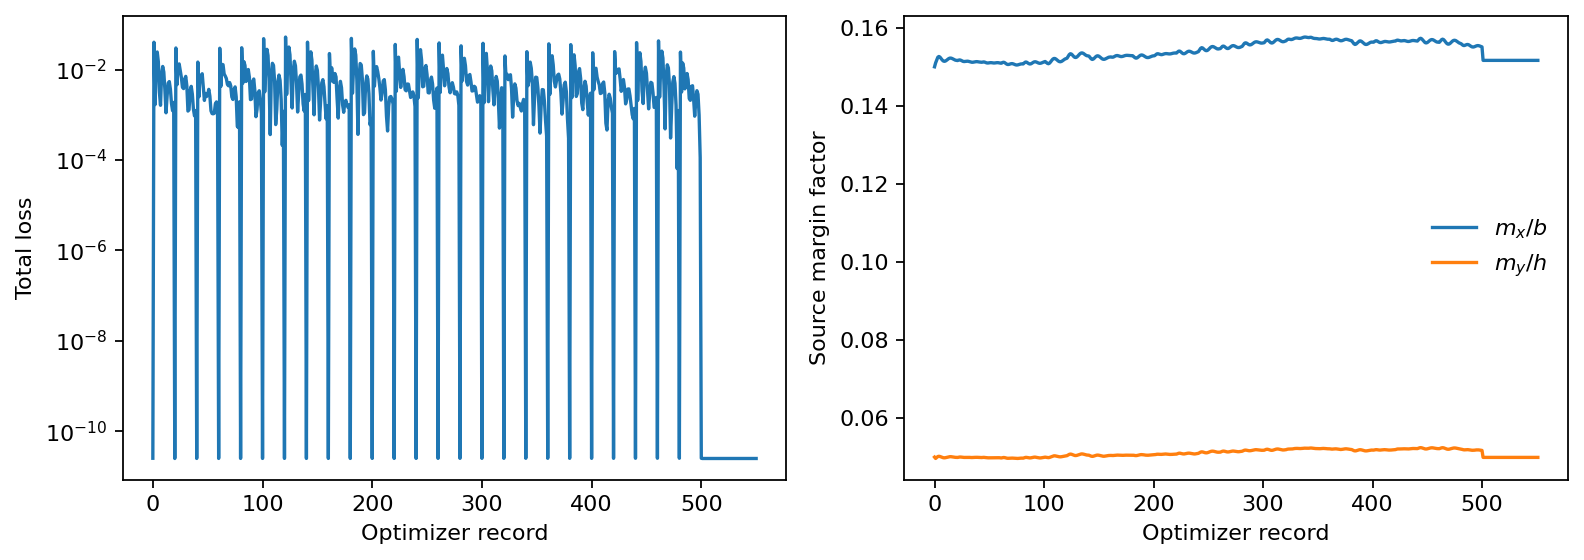

实际源点数量：252，全部绘制。
边界配点条目总数：563，全部绘制。
边界配点去重后坐标数量：560。
  top: 121
  right: 121
  left: 121
  crack: 100
  ligament: 100


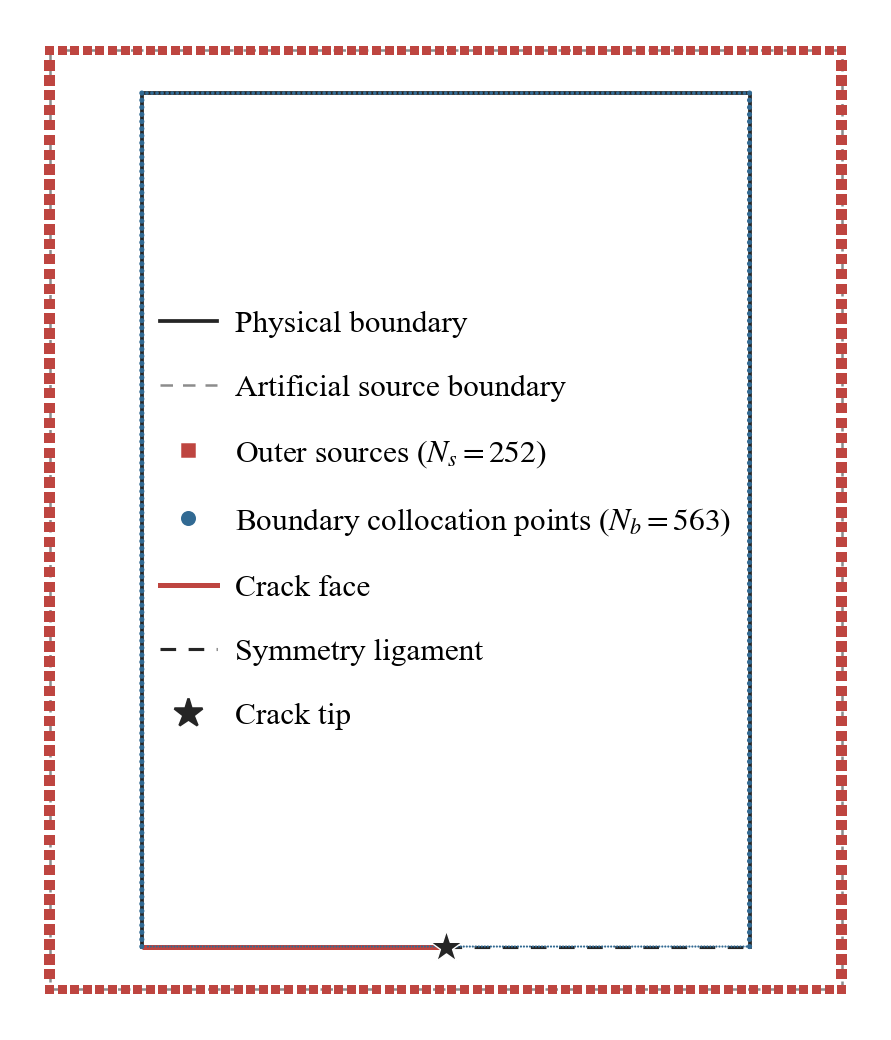

Training time: 29.66s

=== Mode-I center-crack result ===
K_I predicted  : 2.1034081216
K_I reference  : 2.1025451937
relative error : 0.041042%
direct LS K_I  : 2.1034081216
direct LS error: 0.041042%

Boundary loss groups:
  top      : 5.791660e-15
  right    : 2.019268e-13
  left     : 1.627839e-13
  crack    : 9.511535e-14
  ligament : 3.128770e-13
  reg      : 2.213658e-11
  total    : 2.479195e-11

Independent SIF limit checks (finite r includes higher-order terms):
r/a=1.00e-05: stress=2.10342408, upper-face displacement=2.10035088
r/a=3.16e-05: stress=2.10345881, upper-face displacement=2.10167293
r/a=1.00e-04: stress=2.10356878, upper-face displacement=2.10238461
r/a=3.16e-04: stress=2.10391683, upper-face displacement=2.10268650
r/a=1.00e-03: stress=2.10501779, upper-face displacement=2.10254909
r/a=3.16e-03: stress=2.10849865, upper-face displacement=2.10150659
r/a=1.00e-02: stress=2.11949213, upper-face displacement=2.09787469


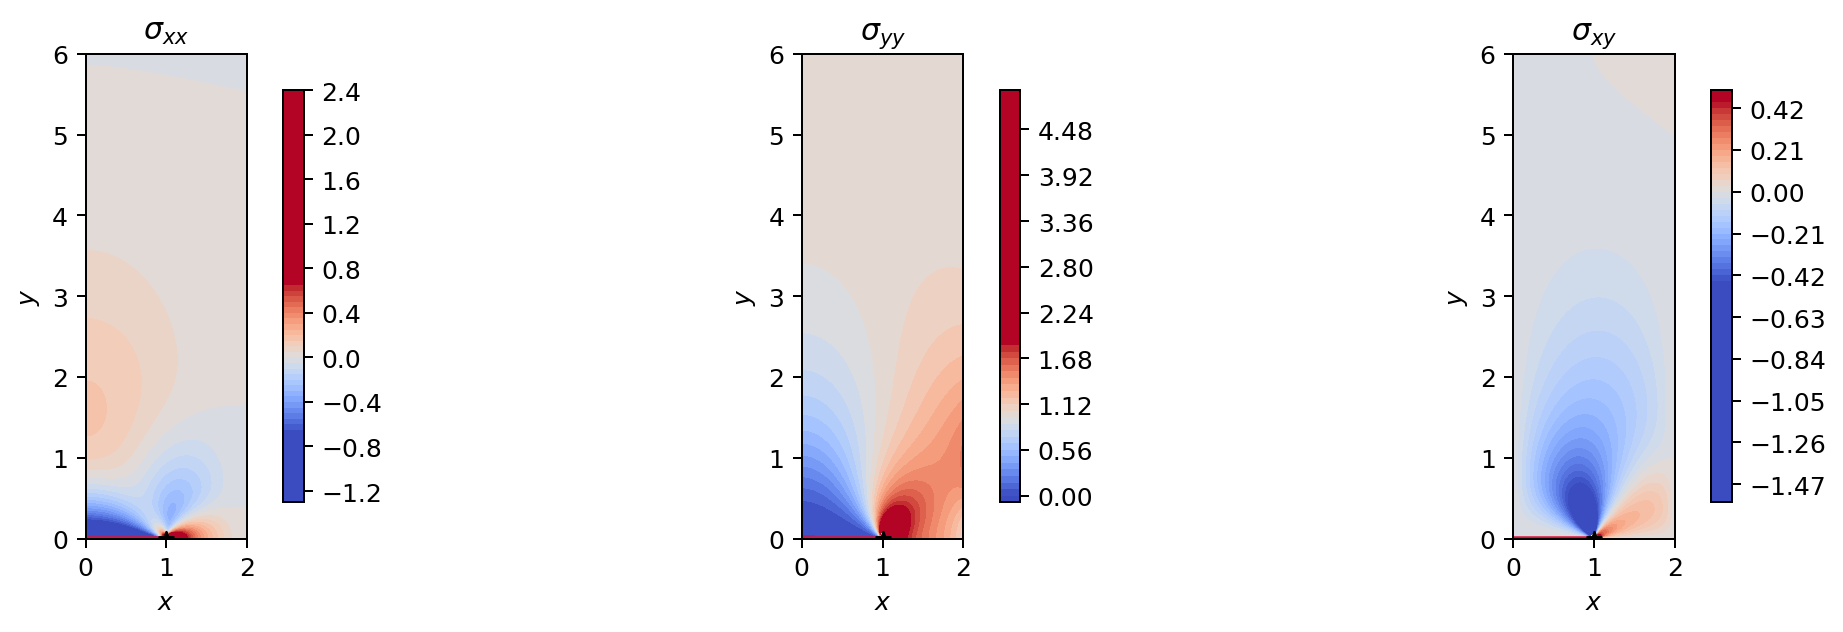

In [11]:

# =========================
# 10) Diagnostics and plotting
# =========================

def solve_same_objective_ls():
    """CPU float64 SVD solve of the SAME regularized training objective.

    No reference SIF enters A, b, initialization or optimization.
    theta = col_scale * physical_coefficients.
    """
    rows, rhs = [], []
    for g, q, target, w in BOUNDARY_BLOCKS:
        block = basis[g][q]
        f = math.sqrt(cfg[w] / block.shape[0])
        rows.append(f * block / col_scale.reshape(1, -1))
        rhs.append(torch.full((block.shape[0], 1), f * float(target), device=device))
    A = torch.cat(rows).detach().cpu().numpy()
    bvec = torch.cat(rhs).detach().cpu().numpy()
    if cfg["lambda_reg"] > 0:
        # Same mean(theta[:-1]**2) as the neural loss: exclude only K_I.
        R = np.eye(n_unknowns, dtype=np.float64)[:-1]
        R *= math.sqrt(cfg["lambda_reg"] / (n_unknowns - 1))
        A = np.vstack((A, R))
        bvec = np.vstack((bvec, np.zeros((n_unknowns - 1, 1))))
    theta, _, rank, sv = scipy_lstsq(A, bvec, cond=cfg["svd_rcond"], lapack_driver="gelsd")
    theta_t = torch.as_tensor(theta, dtype=torch.float64, device=device)
    info = {"rank": int(rank), "unknowns": n_unknowns,
            "objective": float(np.sum((A @ theta - bvec)**2)),
            "condition": float(sv[0] / sv[-1])}
    return theta_t, info


def direct_least_squares_check() -> float:
    theta, _ = solve_same_objective_ls()
    return (theta[-1, 0] / col_scale[-1]).item()



def evaluate_quantities(points: torch.Tensor, batch_size: int = 6000) -> dict[str, np.ndarray]:
    coeff = model.coeffs().detach()
    outs: dict[str, list[torch.Tensor]] = {"ux": [], "uy": [], "sxx": [], "syy": [], "sxy": []}
    for i in range(0, points.shape[0], batch_size):
        batch = points[i:i + batch_size]
        bmat = build_basis_columns(batch)
        for quantity in outs:
            outs[quantity].append((bmat[quantity] @ coeff).detach().cpu())
    return {quantity: torch.cat(values, dim=0).numpy().reshape(-1) for quantity, values in outs.items()}




train_model()

KI_pred = model.coeffs()[-1].detach().item()
rel_err = abs(KI_pred - KI_REF) / abs(KI_REF)
total, detail = boundary_group_losses(model)
KI_ls = direct_least_squares_check()
rel_err_ls = abs(KI_ls - KI_REF) / abs(KI_REF)

print("\n=== Mode-I center-crack result ===")
print(f"K_I predicted  : {KI_pred:.10f}")
print(f"K_I reference  : {KI_REF:.10f}")
print(f"relative error : {rel_err:.6%}")
print(f"direct LS K_I  : {KI_ls:.10f}")
print(f"direct LS error: {rel_err_ls:.6%}")
print("\nBoundary loss groups:")
for key, value in detail.items():
    print(f"  {key:9s}: {value:.6e}")

result_text = "\n".join([
    "K-M complex-potential point-force PIKFNN Mode-I center-crack notebook result",
    f"K_I predicted  : {KI_pred:.10f}",
    f"K_I reference  : {KI_REF:.10f}",
    f"relative error : {rel_err:.6%}",
    f"direct LS K_I  : {KI_ls:.10f}",
    f"direct LS error: {rel_err_ls:.6%}",
    f"final loss     : {total.item():.6e}",
])
Path("km_complex_potential_mode_i_crack_notebook_result.txt").write_text(result_text + "\n", encoding="utf-8")

# Independent near-tip checks. For the upper crack face, uy is HALF the COD.
r_check = a * torch.logspace(-5, -2, 7, device=device)
ahead = torch.column_stack((a + r_check, torch.zeros_like(r_check)))
face = torch.column_stack((a - r_check, torch.zeros_like(r_check)))
fa = evaluate_quantities(ahead)
ff = evaluate_quantities(face)
r_np = r_check.detach().cpu().numpy()
ki_stress = np.sqrt(2*np.pi*r_np) * fa["syy"]
ki_disp = 2*mu/(kappa+1) * np.sqrt(2*np.pi/r_np) * ff["uy"]
print("\nIndependent SIF limit checks (finite r includes higher-order terms):")
for rr, ks, kd in zip(r_np, ki_stress, ki_disp):
    print(f"r/a={rr/a:.2e}: stress={ks:.8f}, upper-face displacement={kd:.8f}")
np.savez("km_williams_coefficients_and_checks.npz",
         coefficients=model.coeffs().detach().cpu().numpy(),
         sources=src_pts.detach().cpu().numpy(), r=r_np,
         ki_stress=ki_stress, ki_displacement=ki_disp,
         ki_pred=KI_pred, ki_reference=KI_REF,
         higher_orders=np.asarray(cfg["higher_williams_orders"]))

x_plot = torch.linspace(0.0, b, cfg["nx_plot"], device=device)
y_plot = torch.linspace(0.0, h, cfg["ny_plot"], device=device)
X, Y = torch.meshgrid(x_plot, y_plot, indexing="xy")
xy_grid = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)

safe = torch.linalg.norm(xy_grid - torch.tensor([a, 0.0], device=device), dim=1) > 1e-12
fields_safe = evaluate_quantities(xy_grid[safe])
fields = {}
for quantity, values in fields_safe.items():
    assembled = np.full(xy_grid.shape[0], np.nan)
    assembled[safe.detach().cpu().numpy()] = values
    fields[quantity] = assembled

sxx_grid = fields["sxx"].reshape(cfg["ny_plot"], cfg["nx_plot"])
syy_grid = fields["syy"].reshape(cfg["ny_plot"], cfg["nx_plot"])
sxy_grid = fields["sxy"].reshape(cfg["ny_plot"], cfg["nx_plot"])
ux_grid = fields["ux"].reshape(cfg["ny_plot"], cfg["nx_plot"])
uy_grid = fields["uy"].reshape(cfg["ny_plot"], cfg["nx_plot"])

X_np = X.detach().cpu().numpy()
Y_np = Y.detach().cpu().numpy()

r_tip = np.sqrt((X_np - a)**2 + Y_np**2)
tip_mask = r_tip < 0.05 * a

plot_fields = []
for field in [sxx_grid, syy_grid, sxy_grid]:
    f = field.copy()
    f[tip_mask] = np.nan
    plot_fields.append(f)

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.4), dpi=180, constrained_layout=True)
plot_data = [
    (plot_fields[0], r"$\sigma_{xx}$", "symmetric"),
    (plot_fields[1], r"$\sigma_{yy}$", "normal"),
    (plot_fields[2], r"$\sigma_{xy}$", "symmetric"),
]

for ax, (data, title, scale_type) in zip(axes, plot_data):
    if scale_type == "symmetric":
        vmax = np.nanpercentile(np.abs(data), 98.5)
        vmin = -vmax
    else:
        vmin = np.nanpercentile(data, 1.0)
        vmax = np.nanpercentile(data, 99.0)

    im = ax.contourf(X_np, Y_np, data, levels=80, cmap="coolwarm", vmin=vmin, vmax=vmax)
    ax.plot([0, a], [0, 0], color="crimson", lw=2.2)
    ax.plot([a, b], [0, 0], color="black", lw=1.2, ls="--")
    ax.scatter([a], [0], s=35, marker="*", color="black", zorder=5)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")
    fig.colorbar(im, ax=ax, shrink=0.85)

plt.savefig("km_complex_potential_crack_stress_contours.png", dpi=600, bbox_inches="tight")
plt.show()

## Relative plate width sweep
Fixed h by default, independent per-case reconstruction and SVD/Adam/L-BFGS; no tip source clusters.
All original globals and random states are restored. Tada reference is used only for evaluation.


b/a=1.10  h/b=5.455  KI=4.80040200  ref=4.79386826  err=0.136%  loss=2.66e-04  L-BFGS 50
b/a=1.15  h/b=5.217  KI=4.01232910  ref=3.99004245  err=0.559%  loss=2.24e-05  L-BFGS 50
b/a=1.20  h/b=5.000  KI=3.53540674  ref=3.52431332  err=0.315%  loss=2.18e-06  L-BFGS 50
b/a=1.30  h/b=4.615  KI=2.99918942  ref=2.99497544  err=0.141%  loss=8.26e-08  L-BFGS 50
b/a=1.40  h/b=4.286  KI=2.70160876  ref=2.69854725  err=0.113%  loss=1.18e-08  L-BFGS 50
b/a=1.50  h/b=4.000  KI=2.51048799  ref=2.50848504  err=0.080%  loss=1.27e-09  L-BFGS 50
b/a=1.60  h/b=3.750  KI=2.37803970  ref=2.37651357  err=0.064%  loss=4.04e-10  L-BFGS 50
b/a=1.70  h/b=3.529  KI=2.28112852  ref=2.27987190  err=0.055%  loss=1.28e-10  L-BFGS 50
b/a=1.80  h/b=3.333  KI=2.20735276  ref=2.20633539  err=0.046%  loss=4.28e-11  L-BFGS 50
b/a=1.90  h/b=3.158  KI=2.14965795  ref=2.14872608  err=0.043%  loss=2.94e-11  L-BFGS 50
b/a=2.00  h/b=3.000  KI=2.10340743  ref=2.10254519  err=0.041%  loss=2.46e-11  L-BFGS 1
b/a=2.50  h/b=2.400  K

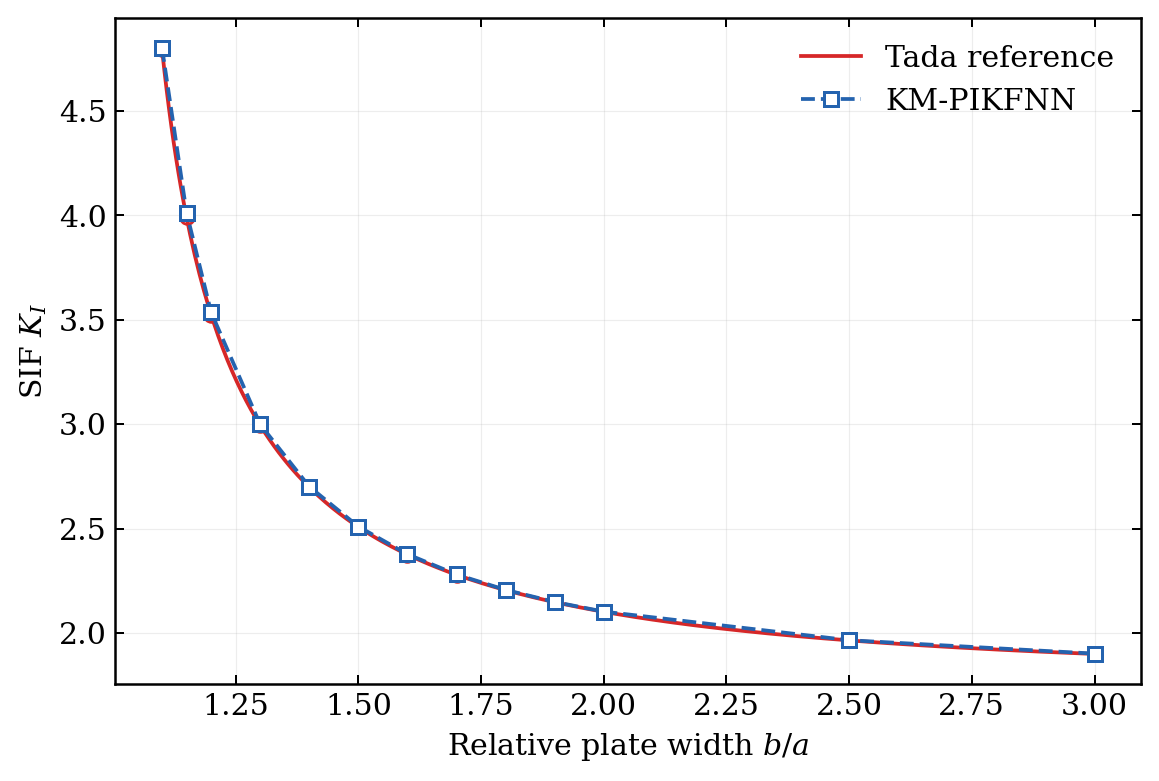

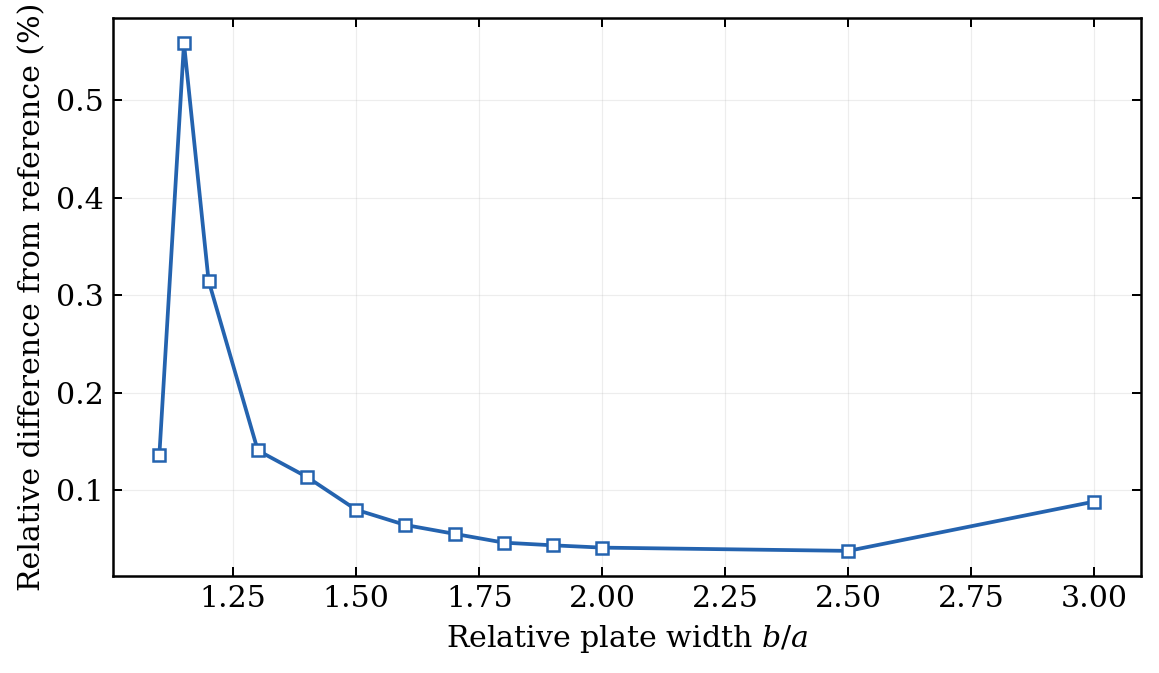

Results saved to: C:\Users\magic\Desktop\KM-PIKFNN\I型裂纹\ba_sif_adaptive_results


In [12]:
# Append this cell AFTER the v3 CPU-basis/GPU-training notebook.
# Exterior sources only. Reference KI is used only for error reporting.
import copy
import csv
import json
import time
from pathlib import Path


def train_model_for_ba_sweep(net,adam_steps=None,lbfgs_epochs=None,lbfgs_max_iter=None,verbose=False):
    return train_adaptive_model(net,adam_steps,lbfgs_epochs,lbfgs_max_iter,verbose)


def run_one_ba_case(ba, base_cfg, adam_steps=None, lbfgs_epochs=None,
                    lbfgs_max_iter=None, verbose=False, height_mode='fixed_h'):
    global cfg, a, b, h, sigma0, bnd_pts, src_pts, basis, n_unknowns, col_scale, model, KI_REF, BOUNDARY_BLOCKS
    if not np.isfinite(ba) or ba <= 1:
        raise ValueError('Require finite b/a > 1 (the ligament must have positive length)')
    cfg = copy.deepcopy(base_cfg)
    cfg['b'] = float(cfg['a']) * float(ba)
    if height_mode == 'fixed_h_over_b':
        cfg['h'] = float(base_cfg['h']) / float(base_cfg['b']) * cfg['b']
    elif height_mode != 'fixed_h':
        raise ValueError('height_mode must be fixed_h or fixed_h_over_b')
    a, b, h, sigma0 = (float(cfg[key]) for key in ['a', 'b', 'h', 'sigma0'])
    # The original ligament sampling starts at 1.02a.
    if b <= 1.02*a:
        raise ValueError('This sampling rule needs b/a > 1.02')
    KI_REF = reference_ki_tada(a_value=a, b_value=b, sigma=sigma0)
    torch.manual_seed(cfg['seed'])
    np.random.seed(cfg['seed'])
    t0 = time.perf_counter()
    bnd_pts = generate_boundary_points()
    src_pts = generate_source_points()
    basis = {name: build_basis_columns(points) for name, points in bnd_pts.items()}
    n_unknowns = basis['top']['ux'].shape[1]
    # Refresh target values explicitly for this case.
    BOUNDARY_BLOCKS = [
        ('top','syy',sigma0,'w_top'), ('top','sxy',0.0,'w_top'),
        ('right','sxx',0.0,'w_right'), ('right','sxy',0.0,'w_right'),
        ('left','ux',0.0,'w_left'), ('left','sxy',0.0,'w_left'),
        ('crack','syy',0.0,'w_crack'), ('crack','sxy',0.0,'w_crack'),
        ('ligament','uy',0.0,'w_ligament'), ('ligament','sxy',0.0,'w_ligament')]
    col_scale = compute_column_scale()
    model = KMPikfnnCrackModel(n_unknowns, col_scale).to(device)
    loss, history, ki_ls, ls_info, origin = train_model_for_ba_sweep(
        model, adam_steps, lbfgs_epochs, lbfgs_max_iter, verbose)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter()-t0
    ki = model.coeffs()[-1].detach().item()
    _, details = boundary_group_losses(model)
    error = abs(ki-KI_REF)/abs(KI_REF)
    print(f'b/a={ba:.2f}  h/b={h/b:.3f}  KI={ki:.8f}  ref={KI_REF:.8f}  '
          f'err={error:.3%}  loss={loss:.2e}  {origin}', flush=True)
    return dict(ba=float(ba), a=a, b=b, h=h, h_over_b=h/b,
                KI_pred=float(ki), KI_ref=float(KI_REF), KI_ls=float(ki_ls),
                KI_normalized=ki/(sigma0*np.sqrt(np.pi*a)),
                rel_err=float(error), rel_err_ls=abs(ki_ls-KI_REF)/abs(KI_REF),
                loss=float(loss), elapsed_seconds=elapsed, history=history,
                best_origin=origin, source_count=len(src_pts), unknown_count=n_unknowns,
                coefficient=model.coeffs().detach().cpu().numpy().reshape(-1),
                source_points=src_pts.detach().cpu().numpy(),
                boundary_losses=details, svd_rank=ls_info['rank'],
                margin_x=float(model.source_factors()[0].detach()),
                margin_y=float(model.source_factors()[1].detach()),
                source_history=model.source_history)


def run_ba_sif_sweep(
    ba_values=(1.10,1.15,1.20,1.30,1.40,1.50,1.60,1.70,1.80,1.90,2.00,2.50,3.00),
    adam_steps=None, lbfgs_epochs=None, lbfgs_max_iter=None, verbose=False,
    height_mode='fixed_h', output_dir='ba_sif_adaptive_results', normalized=False):
    """Scan width with original fixed h by default.

    Alternative fixed_h_over_b preserves the original h/b aspect ratio.
    Tada's finite-width reference does not include h; finite-height effects
    can contribute to the reported error, particularly at larger b/a.
    """
    names = ['cfg','a','b','h','sigma0','bnd_pts','src_pts','basis','n_unknowns',
             'col_scale','model','KI_REF','BOUNDARY_BLOCKS']
    saved = {name: globals()[name] for name in names}
    rng_cpu = torch.get_rng_state()
    rng_cuda = torch.cuda.get_rng_state_all() if device.type == 'cuda' else None
    rng_numpy = np.random.get_state()
    base = copy.deepcopy(cfg)
    values = np.asarray(ba_values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.all(np.isfinite(values)) or np.any(values <= 1.02):
        raise ValueError('Provide at least two finite widths b/a > 1.02')
    if len(np.unique(values)) != len(values):
        raise ValueError('Duplicate b/a values are not allowed')
    values = np.sort(values)
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    results = []
    try:
        for ba in values:
            result = run_one_ba_case(ba, base, adam_steps, lbfgs_epochs,
                                    lbfgs_max_iter, verbose, height_mode)
            results.append(result)
            with (folder/f'source_history_ba_{ba:.6f}.csv').open('w',newline='',encoding='utf-8-sig') as f:
                writer=csv.DictWriter(f,fieldnames=list(result['source_history'][0]))
                writer.writeheader();writer.writerows(result['source_history'])
            # Save each case immediately; completed results survive later failures.
            np.savez(folder / f'case_ba_{ba:.6f}.npz',
                     coefficients=result['coefficient'], sources=result['source_points'],
                     history=np.asarray(result['history']),
                     a=result['a'], b=result['b'], h=result['h'],
                     KI_pred=result['KI_pred'], KI_reference=result['KI_ref'])
    finally:
        globals().update(saved)
        torch.set_rng_state(rng_cpu)
        if rng_cuda is not None:
            torch.cuda.set_rng_state_all(rng_cuda)
        np.random.set_state(rng_numpy)

    keys = ['ba','a','b','h','h_over_b','KI_pred','KI_ref','KI_ls','KI_normalized',
            'rel_err','rel_err_ls','loss','elapsed_seconds','source_count',
            'unknown_count','svd_rank','best_origin','margin_x','margin_y']
    with (folder/'km_pikfnn_sif_vs_ba.csv').open('w',newline='',encoding='utf-8') as f:
        writer=csv.DictWriter(f,fieldnames=keys);writer.writeheader()
        writer.writerows({k:r[k] for k in keys} for r in results)
    (folder/'sweep_settings.json').write_text(json.dumps(
        dict(base_cfg=base, height_mode=height_mode, ba_values=values.tolist(),
             adam_steps=base['adam_steps'] if adam_steps is None else adam_steps,
             lbfgs_epochs=base['lbfgs_epochs'] if lbfgs_epochs is None else lbfgs_epochs,
             lbfgs_max_iter=base['lbfgs_max_iter'] if lbfgs_max_iter is None else lbfgs_max_iter,
             note='Reference is evaluation only; best loss may be the SVD warm start.'),
        indent=2),encoding='utf-8')

    ba=np.array([r['ba'] for r in results])
    predicted=np.array([r['KI_pred'] for r in results])
    reference=np.array([r['KI_ref'] for r in results])
    fine=np.linspace(ba.min(),ba.max(),400)
    fine_ref=np.array([reference_ki_tada(base['a'],base['a']*v,base['sigma0']) for v in fine])
    scale=base['sigma0']*np.sqrt(np.pi*base['a']) if normalized else 1.0
    style={'font.family':'DejaVu Serif','mathtext.fontset':'dejavuserif','font.size':12,
           'axes.linewidth':1.0,'svg.fonttype':'none'}
    with plt.rc_context(style):
        fig,ax=plt.subplots(figsize=(6.6,4.5),dpi=180)
        ax.plot(fine,fine_ref/scale,color='#D62728',lw=1.5,label='Tada reference')
        ax.plot(ba,reference/scale,'o',color='#D62728',ms=5.5,mfc='none',mew=1.1)
        ax.plot(ba,predicted/scale,'--s',color='#2463AF',lw=1.5,ms=5.5,
                mfc='white',mew=1.2,label='KM-PIKFNN',zorder=3)
        ax.set_xlabel(r'Relative plate width $b/a$')
        ax.set_ylabel(r'$K_I/(\sigma_0\sqrt{\pi a})$' if normalized else r'SIF $K_I$')
        ax.tick_params(direction='in',top=True,right=True)
        ax.grid(True,lw=.45,alpha=.22)
        ax.legend(frameon=False)
        fig.tight_layout()
        for ext in ['png','svg']:
            fig.savefig(folder/f'km_pikfnn_sif_vs_ba.{ext}',dpi=600,bbox_inches='tight')
        plt.show();plt.close(fig)
        fig,ax=plt.subplots(figsize=(6.6,3.9),dpi=180)
        ax.plot(ba,100*np.array([r['rel_err'] for r in results]),'-s',
                color='#2463AF',mfc='white',ms=5)
        ax.set_xlabel(r'Relative plate width $b/a$')
        ax.set_ylabel(r'Relative difference from reference (%)')
        ax.tick_params(direction='in',top=True,right=True)
        ax.grid(True,lw=.45,alpha=.22)
        fig.tight_layout()
        fig.savefig(folder/'km_pikfnn_sif_error_vs_ba.png',dpi=600,bbox_inches='tight')
        plt.show();plt.close(fig)
    print(f'Results saved to: {folder.resolve()}')
    return results


ba_sif_results = run_ba_sif_sweep(
    height_mode='fixed_h',  # Same h=6 as the original code; only b changes.
    output_dir='ba_sif_adaptive_results',
    normalized=False,
    verbose=False,
)
